# Present Your Solution: Nutosis

## The short version

**Problem.** Nutosis is a rabies-like disease in the squirrels of Central Park. Animal control gets hundreds of reports a day from the public, can capture only about 40-50 squirrels a day, and each trip costs **\$200**, while each diseased squirrel left in the park costs about **\$1,000**.

**What we built.** A model that reads a report (fur color, age, behavior, place, and the free-text notes) and gives the **probability that the squirrel has nutosis**. Animal control sends an agent when that probability is **20% or more**, the point where a \$200 trip pays for itself against a \$1,000 miss.

**Result on squirrels the model never saw (test set).**
- It cuts the cost by about **\$46,000 per 1,000 reports** compared with today's default of not acting (95% interval about \$29,000 to \$65,000). That is a cost **37% lower**, while reaching **63% of the diseased squirrels** with about 1 trip for every 6 reports.
- Its probabilities are **honest**: squirrels it gives about 44% are diseased 44% of the time, so the 20% rule can be trusted.
- **The memorable finding: fur color is almost everything.** Black squirrels are diseased about 2 times in 3, cinnamon about 1 in 2, gray about 1 in 22. A plain rule "send an agent to every black or cinnamon squirrel" does **as well as the model** on this data.

**Recommendation.** Use the fur-color rule **today** (no software needed), and the model as the system that keeps improving as better reports come in. The single change that would help most is a **"visible symptoms" field in the reporting app** (hair loss, foaming, aggression), because the census does not record the signs of the disease itself.

| Checklist step (Present) | Where |
|---|---|
| 1. Document what you have done | Section 7 |
| 2. Big picture first | The short version, Section 1 |
| 3. Why the solution achieves the business objective | Section 2 |
| 4. What worked, what did not, assumptions and limitations | Sections 5 and 6 |
| 5. Key findings as visuals and easy-to-remember statements | Sections 1 to 4 |

All numbers below are computed in this notebook from `model.pkl` and the two parquet files, so they match the Training notebook. The test set was measured once in the Training notebook, and nothing was changed after that; it is only re-used here to draw the charts.


In [1]:
# Imports
from custom_transformers import *

import joblib
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score

pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 110)

SEED = 42
TARGET = "diseased"
TRIP_COST, MISS_COST = 200, 1000                 # dollars, from the client
THRESHOLD = TRIP_COST / MISS_COST                # send an agent when the probability is at least 20%
COLORS = {"model": "#2a6f97", "baseline": "#b8b8b8", "rule": "#e9a23b", "bad": "#c8553d"}

In [2]:
train = pd.read_parquet("train_set.parquet")
test = pd.read_parquet("test_set.parquet")
model = joblib.load("model.pkl")                 # the final pipeline from the Training notebook: raw sightings in, probabilities out

y_train, y_test = train[TARGET].astype(bool), test[TARGET].astype(bool)
p_test = model.predict_proba(test.drop(columns=[TARGET]))[:, 1]

prep_settings = {k: v for k, v in model.named_steps["prep"].named_steps["features"].get_params().items()}
print(f"Training set: {len(train):,} sightings ({y_train.sum()} diseased) | test set: {len(test):,} sightings ({y_test.sum()} diseased)")
print("Final model:", type(model.named_steps["model"]).__name__,
      "| text setting:", "spaCy" if prep_settings["use_spacy_similarity"] else
      "keywords" if prep_settings["use_keyword_similarity"] else "none")

Training set: 2,418 sightings (303 diseased) | test set: 605 sightings (76 diseased)
Final model: VotingClassifier | text setting: spaCy


## 1. The big picture: what it saves

Five ways to decide where agents go, all scored on the **605 test reports** (76 diseased squirrels), using the client's costs. "Perfect knowledge" is the floor: even then, every diseased squirrel needs a \$200 trip.

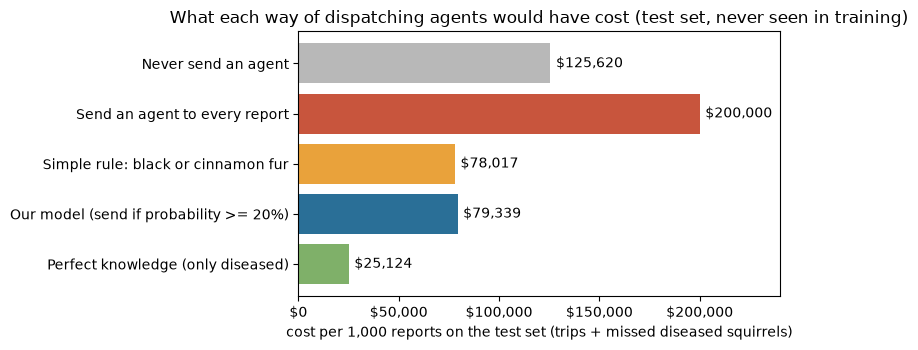

,trips,caught,missed,wasted trips,recall,cost,"cost per 1,000 reports",saved vs never sending
Never send an agent,0,0,76,0,0%,"$76,000","$125,620",$0
Send an agent to every report,605,76,0,529,100%,"$121,000","$200,000","$-74,380"
Simple rule: black or cinnamon fur,101,49,27,52,64%,"$47,200","$78,017","$47,603"
Our model (send if probability >= 20%),100,48,28,52,63%,"$48,000","$79,339","$46,281"
Perfect knowledge (only diseased),76,76,0,0,100%,"$15,200","$25,124","$100,496"


In [3]:
def decision_summary(y, send):
    y, send = np.asarray(y, bool), np.asarray(send, bool)
    caught, missed, trips = int((y & send).sum()), int((y & ~send).sum()), int(send.sum())
    cost = TRIP_COST * trips + MISS_COST * missed
    return {"trips": trips, "caught": caught, "missed": missed, "wasted trips": trips - caught,
            "recall": caught / y.sum(), "cost": cost, "cost per 1,000 reports": 1000 * cost / len(y)}


strategies = {
    "Never send an agent": np.zeros(len(test), bool),
    "Send an agent to every report": np.ones(len(test), bool),
    "Simple rule: black or cinnamon fur": test["Primary Fur Color"].isin(["Black", "Cinnamon"]).to_numpy(),
    "Our model (send if probability >= 20%)": p_test >= THRESHOLD,
    "Perfect knowledge (only diseased)": y_test.to_numpy(),
}
results = pd.DataFrame({name: decision_summary(y_test, send) for name, send in strategies.items()}).T
never_cost = results.loc["Never send an agent", "cost per 1,000 reports"]
results["saved vs never sending"] = never_cost - results["cost per 1,000 reports"]
results = results.astype({c: int for c in ["trips", "caught", "missed", "wasted trips"]})

fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [COLORS["baseline"], COLORS["bad"], COLORS["rule"], COLORS["model"], "#7fb069"]
bars = ax.barh(results.index[::-1], results["cost per 1,000 reports"][::-1], color=colors[::-1])
ax.bar_label(bars, labels=[f"${v:,.0f}" for v in results["cost per 1,000 reports"][::-1]], padding=4)
ax.set_xlabel("cost per 1,000 reports on the test set (trips + missed diseased squirrels)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_xlim(0, results["cost per 1,000 reports"].max() * 1.2)
ax.set_title("What each way of dispatching agents would have cost (test set, never seen in training)")
plt.tight_layout(); plt.show()

shown = results.copy()
for c in ["cost", "cost per 1,000 reports", "saved vs never sending"]:
    shown[c] = shown[c].map("${:,.0f}".format)
shown["recall"] = shown["recall"].map("{:.0%}".format)
shown

**Reading the chart.**
- **Doing nothing is expensive** (\$125,620 per 1,000 reports, all missed squirrels) and **sending to everyone is worse** (\$200,000): about 7 trips in 8 would find a healthy squirrel.
- **The model** sends an agent to about 17% of reports (close to the daily capacity) and catches 48 of the 76 diseased squirrels, for **\$79,339 per 1,000 reports**.
- **The fur-color rule** costs about the same (\$78,017). On this test set the two make almost the same decisions (100 vs 101 trips, 48 vs 49 squirrels caught).

### How sure are we?

The test set has only 76 diseased squirrels, so one lucky or unlucky squirrel changes the cost. The test reports are resampled 2,000 times to get an interval.

In [4]:
# How sure are we? Resample the test reports 2,000 times
rng = np.random.default_rng(SEED)
y_t, send_model = y_test.to_numpy(), strategies["Our model (send if probability >= 20%)"]
send_rule = strategies["Simple rule: black or cinnamon fur"]
save_never, save_rule = [], []
for _ in range(2000):
    i = rng.integers(0, len(y_t), len(y_t))
    model_cost = decision_summary(y_t[i], send_model[i])["cost per 1,000 reports"]
    save_never.append(1000 * MISS_COST * y_t[i].mean() - model_cost)
    save_rule.append(decision_summary(y_t[i], send_rule[i])["cost per 1,000 reports"] - model_cost)
for label, s in [("never sending an agent", save_never), ("the black-or-cinnamon rule", save_rule)]:
    lo, hi = np.percentile(s, [2.5, 97.5])
    print(f"Saving per 1,000 reports compared with {label}: ${np.mean(s):,.0f} (95% interval ${lo:,.0f} to ${hi:,.0f})")

Saving per 1,000 reports compared with never sending an agent: $46,366 (95% interval $29,083 to $65,124)
Saving per 1,000 reports compared with the black-or-cinnamon rule: $-1,281 (95% interval $-4,959 to $1,653)


**Reading it.** The saving against doing nothing is **large and certain** (the whole interval is far above \$0). The difference against the fur-color rule is **about \$1,000 per 1,000 reports and its interval includes 0**: the model and the rule are statistically tied.

## 2. Why it achieves the business objective

The business objective (Frame step) was: **lower the total cost of trips plus missed diseased squirrels, within the daily capacity**, with probabilities that can be trusted. The minimum bar was to beat both "never send" and today's process, with calibrated probabilities.

| Requirement | Result on the test set | Met? |
|---|---|---|
| Cost lower than never sending (\$125,620 / 1,000) | \$79,339 / 1,000, saving \$46,366 (95% interval \$29,083 to \$65,124) | **Yes** |
| Cost lower than sending everywhere (\$200,000 / 1,000) | Yes, by about \$120,000 | **Yes** |
| Within capacity (about 16% of reports a day) | Sends to 17%. With a strict 16% daily cap the cost is \$83,636 (Training, section 11) | **About** |
| Probabilities are honest (calibrated) | Squirrels given about 44% were diseased 44% of the time (section 3) | **Yes** |
| Beat the simple fur-color rule | Tied (difference \$-1,281, interval \$-4,959 to \$1,653) | **No clear gain** |

So the model meets the objective. Most of that comes from one fact, shown below.

### Key finding: fur color is the number-one predictor

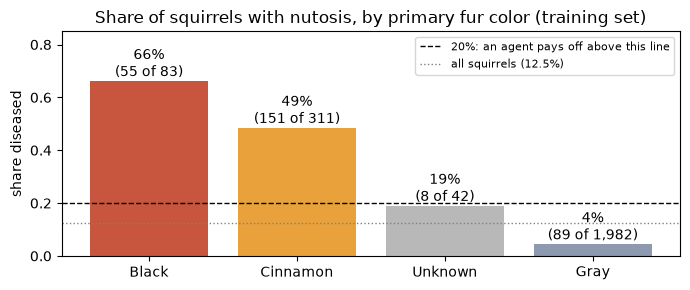

In [5]:
# The number-one finding: fur color (training set only)
by_fur = (train.assign(fur=train["Primary Fur Color"].fillna("Unknown"))
          .groupby("fur")[TARGET].agg(sightings="size", diseased="sum", share="mean")
          .sort_values("share", ascending=False))

fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.bar(by_fur.index, by_fur["share"], color=[COLORS["bad"], COLORS["rule"], COLORS["baseline"], "#8d99ae"])
ax.bar_label(bars, labels=[f"{s:.0%}\n({d} of {n:,})" for s, d, n in zip(by_fur["share"], by_fur["diseased"], by_fur["sightings"])])
ax.axhline(THRESHOLD, color="black", ls="--", lw=1, label="20%: an agent pays off above this line")
ax.axhline(y_train.mean(), color="grey", ls=":", lw=1, label=f"all squirrels ({y_train.mean():.1%})")
ax.set_ylim(0, 0.85); ax.set_ylabel("share diseased"); ax.legend(loc="upper right", fontsize=8)
ax.set_title("Share of squirrels with nutosis, by primary fur color (training set)")
plt.tight_layout(); plt.show()

**Easy to remember: "black or cinnamon, send an agent; gray, don't."** Black and cinnamon squirrels are well above the 20% line, gray squirrels are far below it. Only 4% of gray squirrels are diseased, but they are so many that they still make up 89 of the 303 diseased squirrels in training. Those are the ones nobody can find with this data (section 5).

### What else the model uses

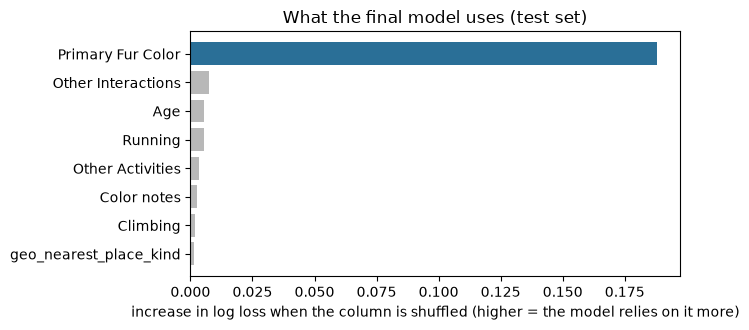

Primary fur color alone accounts for 82% of the total importance.


In [6]:
# What the model relies on: shuffle one input column at a time on the test set and see how much worse the log loss gets
inputs = [c for c in test.columns if c != TARGET]
used = [c for c in REQUIRED_COLUMNS + TEXT_COLUMNS + ["geo_dist_green_m", "geo_dist_water_m", "geo_nearest_place_kind"]
        if c in inputs]
imp = permutation_importance(model, test[inputs], y_test, scoring="neg_log_loss", n_repeats=10, random_state=SEED,
                             n_jobs=1)
importance = pd.Series(imp.importances_mean, index=inputs)[used].sort_values(ascending=False)
top = importance.head(8)[::-1]

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(top.index, top.values, color=[COLORS["model"] if i == len(top) - 1 else COLORS["baseline"] for i in range(len(top))])
ax.set_xlabel("increase in log loss when the column is shuffled (higher = the model relies on it more)")
ax.set_title("What the final model uses (test set)")
plt.tight_layout(); plt.show()
print(f"Primary fur color alone accounts for {importance.iloc[0] / importance.clip(lower=0).sum():.0%} of the total importance.")

**Reading it.** Shuffling the primary fur color makes the log loss worse by about 0.2. Every other column is at least 20 times smaller. The next ones are the **free-text notes** (`Other Interactions`, `Other Activities`, `Color notes`, through the text features of section 4), `Age`, and the `Running` and `Climbing` tick boxes. Place (distances, coordinates, nearest place) and time of day barely matter.

## 3. Can animal control trust the percentages?

The decision rule only works if "20%" really means 1 in 5. The test squirrels are put into 5 equal groups by the probability the model gave them, and each group's real share of diseased squirrels is compared with that probability.

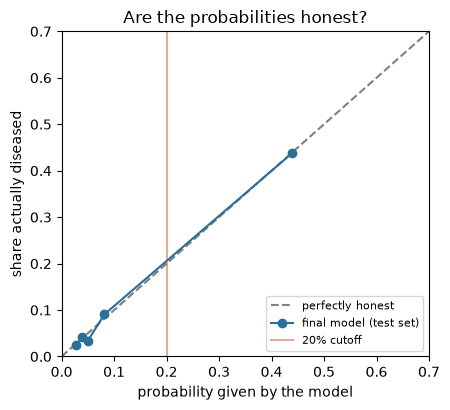

Log loss 0.265 (no model: 0.378) | Brier 0.0762 | AUC 0.850
                      0     1     2     3     4
given              0.03  0.04  0.05  0.08  0.44
actually diseased  0.02  0.04  0.03  0.09  0.44


In [7]:
# Can animal control trust the percentages? Squirrels grouped by the probability the model gave them
frac, pred = calibration_curve(y_test, p_test, n_bins=5, strategy="quantile")
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfectly honest")
ax.plot(pred, frac, "o-", color=COLORS["model"], label="final model (test set)")
ax.axvline(THRESHOLD, color=COLORS["bad"], alpha=0.5, label="20% cutoff")
ax.set_xlim(0, 0.7); ax.set_ylim(0, 0.7)
ax.set_xlabel("probability given by the model"); ax.set_ylabel("share actually diseased"); ax.legend(fontsize=8)
ax.set_title("Are the probabilities honest?")
plt.tight_layout(); plt.show()

print(f"Log loss {log_loss(y_test, p_test):.3f} (no model: {log_loss(y_test, np.full(len(y_test), y_train.mean())):.3f}) | "
      f"Brier {brier_score_loss(y_test, p_test):.4f} | AUC {roc_auc_score(y_test, p_test):.3f}")
print(pd.DataFrame({"given": pred.round(2), "actually diseased": frac.round(2)}).T.to_string())

**Reading it.** The points sit on the diagonal: about 3%, 4%, 5%, 8% and 44% given, and about 2%, 4%, 3%, 9% and 44% found. The probabilities can be read at face value, so they can also be used to **rank** reports on busy days (send the highest first) and to explain each trip to the agents. Log loss 0.265 against 0.378 with no model.

## 4. Text processing: what the free-text notes add

The census has three free-text columns (`Color notes`, `Other Activities`, `Other Interactions`). Two ways of reading them were built in the Preparation notebook and compared in the Training notebook (section 6c):

| Method | How it reads a note | Result in cross-validation (change in log loss, 2 models) |
|---|---|---|
| "Has a note" flag | Did the volunteer write anything? | Better in 5/5 folds (-0.007 and -0.010) |
| Keyword similarity (TF-IDF of word stems) | Shares a word with the symptom keywords? Only 11 notes do | No gain beyond the flag. The final search still switched it on (it costs nothing) |
| **spaCy word vectors** (Text Processing notebook) | Average word vector of the note, cosine similarity to symptom concepts such as "foaming at the mouth" | **Best: better in 5/5 folds (-0.008 and -0.013)**, a little beyond the flag. Every tuning search switched it on. **Used in the final model** |

Sightings with a note: 572 of 2,418 (24%)
Share diseased: with a note 18.4% | without a note 10.7%
Notes containing a symptom keyword (kw_any > 0): 11


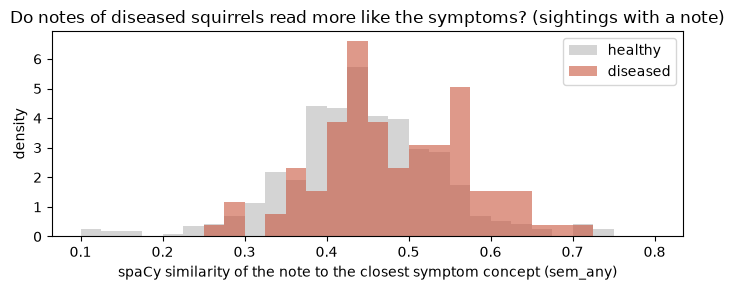

Median sem_any of the notes: diseased 0.47 | healthy 0.44


In [8]:
# Text processing: what the free-text notes add (training set, no model)
features = SquirrelFeatures(use_keyword_similarity=True, use_spacy_similarity=True).fit(train)
notes = features._notes(train)
kw = features.keyword_.transform(notes)
sem = features.spacy_.transform(notes)

has_note = kw["has_note"] == 1
print(f"Sightings with a note: {has_note.sum():,} of {len(train):,} ({has_note.mean():.0%})")
print(f"Share diseased: with a note {y_train[has_note].mean():.1%} | without a note {y_train[~has_note].mean():.1%}")
print(f"Notes containing a symptom keyword (kw_any > 0): {int((kw['kw_any'] > 0).sum())}")

fig, ax = plt.subplots(figsize=(7, 3))
bins = np.linspace(0.1, 0.8, 29)
ax.hist(sem.loc[has_note & ~y_train, "sem_any"], bins=bins, alpha=0.6, density=True, label="healthy", color=COLORS["baseline"])
ax.hist(sem.loc[has_note & y_train, "sem_any"], bins=bins, alpha=0.6, density=True, label="diseased", color=COLORS["bad"])
ax.set_xlabel("spaCy similarity of the note to the closest symptom concept (sem_any)"); ax.set_ylabel("density")
ax.set_title("Do notes of diseased squirrels read more like the symptoms? (sightings with a note)")
ax.legend(); plt.tight_layout(); plt.show()
print("Median sem_any of the notes: diseased "
      f"{sem.loc[has_note & y_train, 'sem_any'].median():.2f} | healthy {sem.loc[has_note & ~y_train, 'sem_any'].median():.2f}")

**Reading it.**
- **Squirrels with a note are diseased more often** (18% vs 11%). A volunteer writes something when a squirrel stands out, and diseased squirrels stand out more.
- **Notes of diseased squirrels read slightly more like the symptoms** (median similarity 0.47 vs 0.44). The difference is small but consistent across all four themes, and spaCy catches it because it matches **meaning**: a note does not need the word "aggressive" to sit close to "aggressive attacking and biting".
- **It is a weak signal and an easily fooled one.** "nut in mouth" looks like "foaming at the mouth" to an averaged vector. The notes are second in importance, far behind fur color.
- **It needs the app.** These features only work if the reporting app keeps a free-text box, and the computer running the model needs spaCy and `en_core_web_lg`.

## Searching the reports with plain words

Animal control and the public describe squirrels in words ("a black one going after people near the pond"). Two text tools from `custom_transformers.py` let anyone search the reports that way:

- `describe_sightings(...)` turns each report's columns into one readable sentence (fur, age, where it was, behaviors ticked, the notes, the place).
- `search_sightings(reports, "query")` ranks reports by **how many of the query's words they contain** (word stems, so "approaching" finds "approaches"), plus **pairs of words found side by side** (so "cinnamon squirrel" puts a cinnamon squirrel above a gray one with cinnamon highlights), and then by **spaCy similarity** (meaning, so "chasing a dog" also finds a note like "chased by dog #2"). The label is never used to rank.

Below, a few searches on the **training** reports, with the share of diseased squirrels among the 30 best matches (all training reports: 12.5%).

In [9]:
queries = ["black squirrel approaching people", "cinnamon squirrel near the pond",
           "aggressive squirrel chasing a dog", "sick looking squirrel with patchy fur",
           "gray squirrel eating and foraging"]
rows = []
for q in queries:
    hits = search_sightings(train, q, top=30)
    rows.append({"query": q, "share diseased in the 30 best matches": f"{hits[TARGET].mean():.0%}",
                 "best match": hits["description"].iloc[0][:110]})
display(pd.DataFrame(rows).set_index("query"))

print("Top 5 for 'aggressive squirrel chasing a dog':")
search_sightings(train, "aggressive squirrel chasing a dog", top=5)[["words_matched", "phrases_matched", "similarity", "description", TARGET]]

,share diseased in the 30 best matches,best match
query,,
black squirrel approaching people,73%,"Adult Black squirrel. Above Ground. AM. Seen: foraging, approaches."
cinnamon squirrel near the pond,20%,"Adult Cinnamon squirrel with Gray highlights. Ground Plane. PM. Seen: foraging, runs from. Near The Pond (..."
aggressive squirrel chasing a dog,23%,"Adult Gray squirrel with White highlights. Ground Plane. PM. Seen: chasing, runs from. Notes: partial miss..."
sick looking squirrel with patchy fur,13%,Adult Cinnamon squirrel with Gray and White highlights. PM. Seen: indifferent. Notes: white patches. almos...
gray squirrel eating and foraging,7%,"Adult Gray squirrel. Ground Plane. AM. Seen: eating, foraging."


Top 5 for 'aggressive squirrel chasing a dog':


,words_matched,phrases_matched,similarity,description,diseased
512,0.67,0.33,0.784,"Adult Gray squirrel with White highlights. Ground Plane. PM. Seen: chasing, runs from. Notes: partial miss...",True
2257,0.67,0.33,0.726,"Adult Gray squirrel. Ground Plane. PM. Seen: running, climbing, kuks, runs from. Notes: chased by dog #2 r...",False
315,0.67,0.33,0.723,Adult Gray squirrel with White highlights. Above Ground. PM. Notes: chased by dog. Place: in tree.,False
2047,0.67,0.33,0.718,"Adult Gray squirrel with Cinnamon highlights. Ground Plane. PM. Seen: running, climbing, kuks, runs from. ...",False
727,0.67,0.33,0.710,"Adult Gray squirrel with White highlights. Ground Plane. PM. Seen: running, runs from. Notes: (very brown)...",False


**Reading it.**
- **"black squirrel approaching people"** finds the riskiest reports: about 3 in 4 of the best 30 matches are diseased (12.5% on average). It is the two strongest signals of the model, found with plain words.
- **"gray squirrel eating and foraging"** finds ordinary squirrels: under 1 in 10 is diseased.
- **"aggressive squirrel chasing a dog"** doubles the average (about 1 in 4). It finds chases and dog encounters, partly through the notes ("chased by dog"), which is what the word and meaning matching add.
- **"sick looking squirrel with patchy fur"** is no better than average, because the census never describes symptoms; its best matches are color notes ("white patches"). The same limit as in section 4.
- **"cinnamon squirrel near the pond"** is only about average: few cinnamon squirrels were seen near a pond, so the list fills with gray squirrels that have cinnamon highlights. A search finds what was written, it does not predict.

So the search is a quick tool for a dispatcher (find a report someone phones in about) or a public-information page ("what do reports of sick squirrels look like?"), while the model does the ranking.

## Example: a dispatch list

How it would look for animal control on one test day: every report gets a probability, the list is sorted, and agents go down the list while the probability is 20% or more (and capacity lasts). `where to go` is the plain-language place built from the USGS names in the Get the Data step. The last column is only known hours later, after the blood test.

In [10]:
# How animal control would use it: one test day, the reports ranked by probability
DAILY_CAPACITY = 45
day = test["date"].value_counts().idxmax()
one_day = test[test["date"] == day].assign(probability=p_test[(test["date"] == day).to_numpy()])
one_day = one_day.sort_values("probability", ascending=False)
send_today = one_day["probability"] >= THRESHOLD
print(f"{day:%A %B %d, %Y}: {len(one_day)} test reports, {int(send_today.sum())} at 20% or more "
      f"(capacity about {DAILY_CAPACITY} a day for all reports, the test set is 20% of them)")
dispatch = one_day.head(8)[["probability", "Primary Fur Color", "Shift", "geo_where_text", TARGET]].copy()
dispatch["probability"] = dispatch["probability"].map("{:.0%}".format)
dispatch.rename(columns={"geo_where_text": "where to go", TARGET: "(later found diseased?)"}).reset_index(drop=True)

Sunday October 07, 2018: 92 test reports, 18 at 20% or more (capacity about 45 a day for all reports, the test set is 20% of them)


,probability,Primary Fur Color,Shift,where to go,(later found diseased?)
0,76%,Black,PM,"About 208 m east of The Pond (Lake), New York County, NY (lat 40.76668, lon -73.97183)",True
1,70%,Black,AM,"About 460 m south of The Pool (Lake), New York County, NY (lat 40.79059, lon -73.95982)",True
2,60%,Cinnamon,PM,"About 399 m south-east of Turtle Pond (Lake), New York County, NY (lat 40.77789, lon -73.96398)",False
3,58%,Black,PM,"About 290 m north-east of The Pond (Lake), New York County, NY (lat 40.76726, lon -73.97112)",False
4,58%,Cinnamon,AM,"About 267 m south of Turtle Pond (Lake), New York County, NY (lat 40.77731, lon -73.96821)",True
5,53%,Black,AM,"About 143 m south-east of The Pool (Lake), New York County, NY (lat 40.79350, lon -73.96010)",False
6,50%,Black,AM,"About 454 m south of The Pool (Lake), New York County, NY (lat 40.79066, lon -73.95970)",False
7,50%,Cinnamon,PM,"About 425 m south-east of Turtle Pond (Lake), New York County, NY (lat 40.77765, lon -73.96382)",False


**Reading it.** 4 of the top 6 are black, the rest cinnamon, which is the fur-color finding again. 2 of the top 4 turned out diseased, and 3 of the top 8. With a 20% cutoff that is expected: a trip pays off on average, not every time.

## 5. What worked, what did not, and interesting points

**What worked**
- **Framing it as a probability, not a yes/no.** The 20% cutoff falls straight out of the costs (\$200 / \$1,000), and the calibration shows the probabilities can be used directly.
- **Fur color**, found in the Frame step and confirmed everywhere since.
- **Cross-validation that keeps whole squirrels (and, for the weather test, whole days) apart.** It stopped the day-level weather columns from looking useful when they only recognised days already seen.
- **spaCy word vectors for the notes** gave a small, consistent gain that the keyword list could not, because the real notes never use the symptom words.
- **A tuned ensemble.** A weighted average of tuned extra trees, logistic regression, SVM and gradient boosting, with the weights and the preparation searched together (19 hyperparameters), gave the best probabilities in cross-validation, clearly better than a plain average (log loss 0.254 against 0.263).
- **Searching the preparation with the model.** Each model was tuned over 11 preparation settings plus its own hyperparameters (14 to 19 in all). All of them chose the spaCy text features.

**What did not work**
- **Beating the fur-color rule.** Every model ends up mostly repeating it. The other columns only move probabilities a little.
- **Symptom keywords.** "Foaming", "mangy" and "aggressive" do not appear in the census at all, so the keyword method matched only 11 notes.
- **Weather and calendar.** Only 11 days, so they acted as a "which day" code and did not help on unseen days.
- **Location.** The map showed no clear hotspots, and distances to water, woods and hills hardly matter.

**Interesting points**
- About 1 diseased squirrel in 3 is a **gray** squirrel that looks normal in every column. With this data no model can find them (they are why recall is stuck around 64-70%).
- **Whether a volunteer wrote a note** says more than what the note says.
- On 2 of the 11 census days there were more diseased squirrels (52 and 74) than a team can capture in a day, so even a perfect model could not catch them all.

## 6. Assumptions and limitations

| Assumption or limit | Why it matters |
|---|---|
| Squirrels not in `diseased.csv` are healthy | If some were never tested, the real share of disease is higher and the model under-estimates |
| The census stands in for the reporting app | The app may have different fields. In particular the notes and the fur color must be collected the same way |
| Only 11 days in October 2018, one park | Not tested on another season or year. Retrain when new data comes in |
| Costs are fixed at \$200 and \$1,000 | If they change, the cutoff changes: cutoff = trip cost / miss cost |
| Capacity of about 16% of reports a day | Assumes a census day looks like a real day of reports |
| Small test set (76 diseased) | Results are given with intervals. Differences of a few thousand dollars per 1,000 reports are noise |
| The notes need spaCy | `model.pkl` needs `custom_transformers.py`, spaCy and `en_core_web_lg` installed to load |
| The census does not record the symptoms | The main limit: a gray squirrel with nutosis looks healthy in every column |

## 7. What we did (documentation)

| Step | Notebook | What was done |
|---|---|---|
| Frame the problem | `Nutosis.ipynb` | Business objective, costs and the 20% break-even, baselines, metrics (log loss, cost, calibration), assumptions checked |
| Get the data | `Nutosis.ipynb` | Census + labels, two outside sources (USGS place names, with places outside the park removed, and NOAA weather + calendar), cached downloads, 80/20 split by squirrel, `train_set.parquet` / `test_set.parquet` |
| Explore | `Nutosis - Exploration.ipynb` | Every column studied, fur color and `Approaches` found, keyword search of the notes, transformations listed |
| Prepare | `Nutosis - Preparation.ipynb` | Cleaning, feature selection, height and highlight features, keyword and spaCy text features, scaling, `preprocessor.pkl`. Text search tools (`describe_sightings`, `search_sightings`) in `custom_transformers.py` |
| Short-list and fine-tune | `Nutosis - Training.ipynb` | 8 model families, importance, error analysis, column-group, weather and text tests, random searches over 14 to 19 hyperparameters per model (11 in the preparation), calibration, a tuned ensemble (19 hyperparameters), test set once, `model.pkl` |
| Present | this notebook | Summary and charts |
| Launch | not done | Not part of this project |

**Next steps we would recommend**
1. Add a **"visible symptoms" question** to the reporting app (hair loss, foaming, unusual aggression: yes / no). It is the information a human would use, and the census lacks it.
2. **Keep a free-text box** in the app, since the notes help a little.
3. **Log every report's probability and the blood test result**, and compare them monthly with the calibration chart above. Retrain when they drift or a new season of data arrives.
4. **Measure what was assumed.** Once agents use the list, record which reported squirrels were tested and how many trips were made each day: this checks the two assumptions the results rest on (untested squirrels are healthy, and about 45 trips a day).
